# EDA (Exploratory Data Analysis)

# Importing Libraries

In [2]:
import pandas as pd
import numpy as np

# Reading the dataset

In [3]:
df = pd.read_csv("../data/retailhive_10k.csv")

# View the First 5 Rows

In [4]:
df.head()

,product_title,rating,transaction_id,date,channel,region,customer_id,quantity,price,revenue
0,The Dirty Little Secrets of Getting Your Dream...,Four,1,2020-05-02,Store,US,13068,3,35.370401,106.111202
1,Mesaerion: The Best Science Fiction Stories 18...,One,2,2025-07-20,Online,Asia,40027,4,32.506908,130.027634
2,Libertarianism for Beginners,Two,3,2024-07-30,Online,US,40294,3,47.085821,141.257464
3,On a Midnight Clear,Three,4,2020-04-08,Mobile,US,19924,3,14.811784,44.435351
4,Online Marketing for Busy Authors: A Step-By-S...,One,5,2024-09-27,Mobile,Europe,40383,3,51.179701,153.539102


# Understand the Dataset Structure

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   product_title   12000 non-null  object 
 1   rating          12000 non-null  object 
 2   transaction_id  12000 non-null  int64  
 3   date            12000 non-null  object 
 4   channel         12000 non-null  object 
 5   region          12000 non-null  object 
 6   customer_id     12000 non-null  int64  
 7   quantity        12000 non-null  int64  
 8   price           12000 non-null  float64
 9   revenue         12000 non-null  float64
dtypes: float64(2), int64(3), object(5)
memory usage: 937.6+ KB


# Check the Dataset Shape

In [6]:
df.shape

(12000, 10)

# Display All Column Names

In [7]:
df.columns

Index(['product_title', 'rating', 'transaction_id', 'date', 'channel',
       'region', 'customer_id', 'quantity', 'price', 'revenue'],
      dtype='object')

# Understand the Data Statistically

In [8]:
df.describe()

,transaction_id,customer_id,quantity,price,revenue
count,12000.00000,12000.000000,12000.000000,12000.000000,12000.000000
mean,6000.50000,30155.073083,2.975250,34.731508,103.383174
std,3464.24595,11501.173351,1.411726,15.201040,70.156603
min,1.00000,10000.000000,1.000000,8.136418,8.343938
25%,3000.75000,20202.750000,2.000000,20.499012,47.803286
50%,6000.50000,30259.000000,3.000000,34.441834,85.475147
75%,9000.25000,40201.500000,4.000000,47.102572,144.709868
max,12000.00000,49996.000000,5.000000,69.707900,344.725460


# Check Missing Values

In [9]:
df.isnull().sum()

product_title     0
rating            0
transaction_id    0
date              0
channel           0
region            0
customer_id       0
quantity          0
price             0
revenue           0
dtype: int64

# Check Duplicate Records

In [10]:
df.duplicated().sum()

0

# Covert the date column to datetime

In [11]:
df["date"] = pd.to_datetime(df["date"])

# Verify the Conversion

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   product_title   12000 non-null  object        
 1   rating          12000 non-null  object        
 2   transaction_id  12000 non-null  int64         
 3   date            12000 non-null  datetime64[ns]
 4   channel         12000 non-null  object        
 5   region          12000 non-null  object        
 6   customer_id     12000 non-null  int64         
 7   quantity        12000 non-null  int64         
 8   price           12000 non-null  float64       
 9   revenue         12000 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(3), object(4)
memory usage: 937.6+ KB


# Channel Distribution 

 Frequency of transaction/channel

In [13]:
df["channel"].value_counts()

Mobile    4048
Store     4029
Online    3923
Name: channel, dtype: int64

Total revenue/channel

In [14]:
df.groupby("channel")["revenue"].sum()

channel
Mobile    425080.450759
Online    397369.223552
Store     418148.410298
Name: revenue, dtype: float64

Average revenue/channel

In [15]:
df.groupby("channel")["revenue"].mean()

channel
Mobile    105.009993
Online    101.292180
Store     103.784664
Name: revenue, dtype: float64

# Regional Analysis

Transaction count by reigon

In [16]:
df["region"].value_counts()

US        4022
Europe    4008
Asia      3970
Name: region, dtype: int64

Total revenue by region

In [17]:
df.groupby("region")["revenue"].sum()

region
Asia      414908.367864
Europe    420232.865926
US        405456.850819
Name: revenue, dtype: float64

# Trend Analysis

Monthly revenue trend

In [18]:
df.groupby(df["date"].dt.month)["revenue"].sum()

date
1     100453.480837
2      92514.983009
3     112582.947548
4     103895.016274
5     110167.478815
6     102162.691682
7     104913.295578
8     102621.488369
9      97316.225773
10    108073.336236
11    106264.816025
12     99632.324463
Name: revenue, dtype: float64

Weekly revenue trend

In [19]:
df.groupby(df["date"].dt.day_name())["revenue"].sum()

date
Friday       174736.838750
Monday       173815.168999
Saturday     172486.594709
Sunday       178072.707541
Thursday     179771.521212
Tuesday      181003.461659
Wednesday    180711.791738
Name: revenue, dtype: float64

# Customer Segmentation

We want to classify customers into One time buyers, Occasional Buyer and Frequent buyer

Step 1: Count Transactions/Customer

In [20]:
customer_transactions = df.groupby("customer_id").size()

Step 2: Display the result

In [21]:
customer_transactions.head(10)

customer_id
10000    1
10005    1
10011    1
10016    2
10019    1
10024    1
10028    1
10030    1
10048    1
10051    1
dtype: int64

Step 3: Create customer segments

In [22]:
customer_segments = customer_transactions.apply(
lambda x: "One-Time Buyer" if x == 1
else "Occasional Buyer" if x <= 5
else "Frequent Buyer"
)

Step 4: Display the customer segments

In [23]:
customer_segments.head(10)

customer_id
10000      One-Time Buyer
10005      One-Time Buyer
10011      One-Time Buyer
10016    Occasional Buyer
10019      One-Time Buyer
10024      One-Time Buyer
10028      One-Time Buyer
10030      One-Time Buyer
10048      One-Time Buyer
10051      One-Time Buyer
dtype: object

In [24]:
customer_segments.value_counts()

One-Time Buyer      8873
Occasional Buyer    1485
dtype: int64

# Product Analysis

Top 10 products by revenue

In [25]:
df.groupby("product_title")["revenue"].sum().sort_values(ascending=False).head(10)

product_title
The Murder That Never Was (Forensic Instincts #5)                                     22989.375127
The Electric Pencil: Drawings from Inside State Hospital No. 3                        22550.116040
Slow States of Collapse: Poems                                                        22146.559958
Our Band Could Be Your Life: Scenes from the American Indie Underground, 1981-1991    21232.922282
Behind Closed Doors                                                                   21024.987096
Judo: Seven Steps to Black Belt (an Introductory Guide for Beginners)                 20730.276481
Aladdin and His Wonderful Lamp                                                        20629.623428
Rat Queens, Vol. 3: Demons (Rat Queens (Collected Editions) #11-15)                   20456.303863
A Light in the Attic                                                                  20395.447516
The Past Never Ends                                                                   20246.028

# Statistical Analysis

# Part 1: Descriptive Statistics

Step 1: Mean, Median and mode

In [26]:
df["revenue"].mean()

103.38317371741054

In [27]:
df["revenue"].median()

85.47514669752483

In [28]:
df["revenue"].mode()

0          8.343938
1          8.530988
2          8.735058
3          8.752918
4          8.838575
            ...    
11995    336.655159
11996    337.834346
11997    341.469525
11998    342.408182
11999    344.725460
Name: revenue, Length: 12000, dtype: float64

Lets compare mean and median 
Mean: 103.38
Mode: 85.48

 Mean > Median

Step 2: Variance and Standard Deviation

In [29]:
df["revenue"].var()

4921.948889178682

In [30]:
df["revenue"].std()

70.15660260573257

Step 3: Skewness

In [31]:
df["revenue"].skew()

0.943948512827636

Step 4: Kurtosis

In [32]:
df["revenue"].kurt()

0.2079958667663644

# Part 2: Distribution Analysis

Step 1: Histogram

Import Library

In [33]:
import matplotlib.pyplot as plt

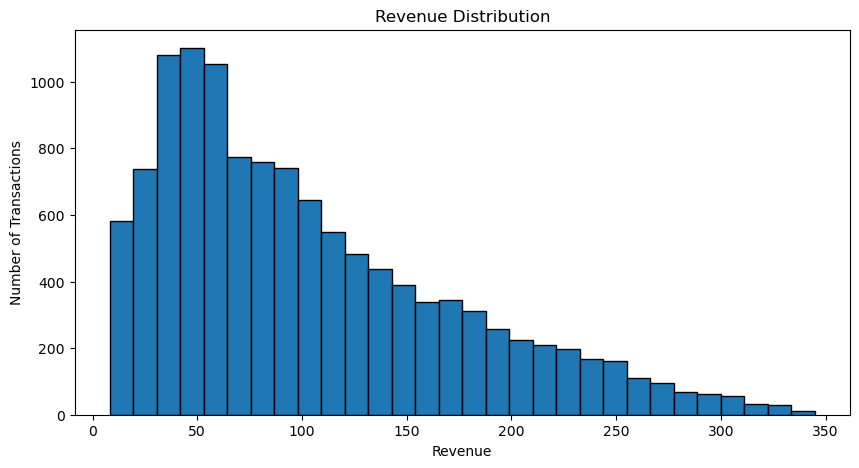

In [34]:
plt.figure(figsize=(10,5))

plt.hist(df["revenue"], bins=30, edgecolor="black")

plt.title("Revenue Distribution")
plt.xlabel("Revenue")
plt.ylabel("Number of Transactions")

plt.show()

Step 2: BoxPlot

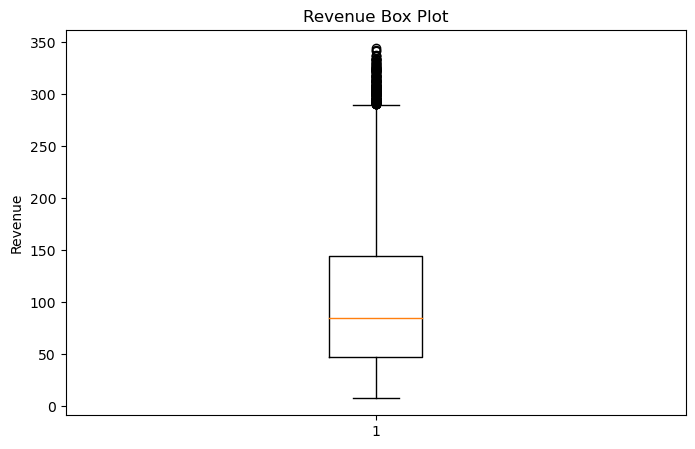

In [35]:
plt.figure(figsize=(8,5))

plt.boxplot(df["revenue"])

plt.title("Revenue Box Plot")
plt.ylabel("Revenue")

plt.show()

Step 3: Distribution Interpretation

In this, we interpret the histogram and box plot together 

From the histogram:

Most revenue values are concentrated in the lower and middle revenue range.
The graph has a long tail towards the right.
This visually confirms the positive skewness (0.944).

From the box plot:

The median is closer to the lower quartile.
There are several points above the upper whisker.
These points represent high-value revenue transactions (outliers).

# Part C: Correlation Analysis

Step 1: Correlation Matrix

In [36]:
df[["price","quantity","revenue"]].corr()

,price,quantity,revenue
price,1.000000,0.002249,0.645014
quantity,0.002249,1.000000,0.701199
revenue,0.645014,0.701199,1.000000


Step 2: Correlation Heatmap

Import Library

In [37]:
import seaborn as sns

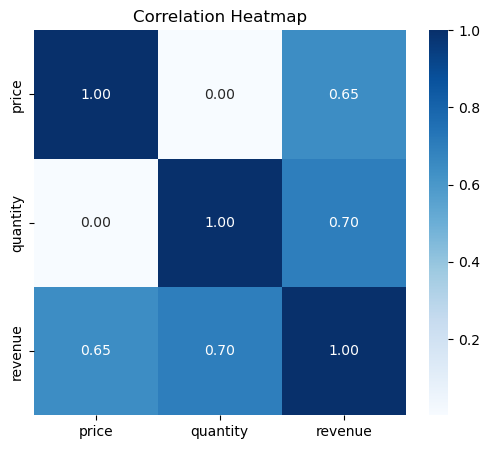

In [38]:
plt.figure(figsize=(6,5))

sns.heatmap(
    df[["price", "quantity", "revenue"]].corr(),
    annot=True,
    cmap="Blues",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

# Part D: Relationship Analysis

Step 1: Scatter Plot

A) Prive vs Revenue

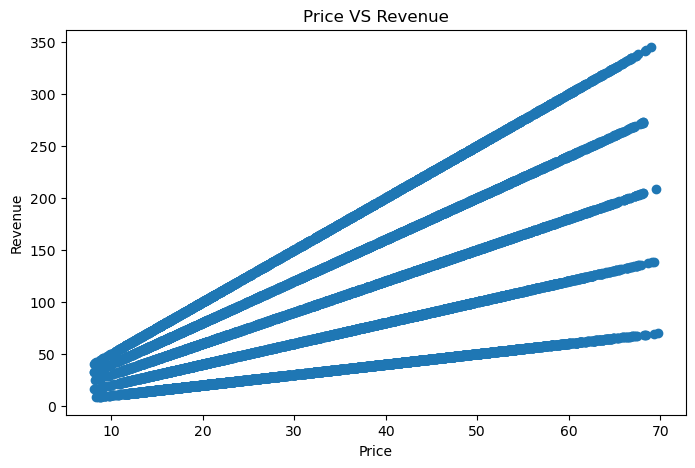

In [39]:
plt.figure(figsize=(8,5))
plt.scatter(df["price"],df["revenue"])
plt.title("Price VS Revenue")
plt.xlabel("Price")
plt.ylabel("Revenue")
plt.show()

B) Quantity VS Revenue

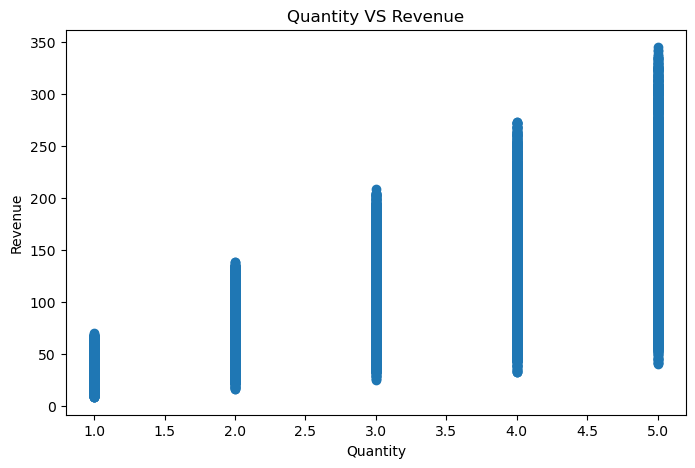

In [40]:
plt.figure(figsize=(8,5))
plt.scatter(df["quantity"],df["revenue"])
plt.title("Quantity VS Revenue")
plt.xlabel("Quantity")
plt.ylabel("Revenue")
plt.show()

# Part E: Outlier Detection (IQR Method)

Step 1: Calculate Q1 and Q3

In [41]:
q1 = df["revenue"].quantile(0.25)
q3 = df["revenue"].quantile(0.75)

print("Q1:",q1)
print("Q3:",q3)

Q1: 47.80328623767099
Q3: 144.709867723964


Step 2: Calculate IQR

In [42]:
IQR = q3 - q1

print("IQR:", IQR)

IQR: 96.90658148629302


Step 3: Calculate Lower and Upper Bound

In [43]:
lower_bound = q1 - (1.5 * IQR)
upper_bound = q3 + (1.5 * IQR)

print("Lower Bound:",lower_bound)
print("Upper Bound:",upper_bound)

Lower Bound: -97.55658599176854
Upper Bound: 290.06973995340354


Step 4: Detect Outliers

In [44]:
outliers = df[(df["revenue"] < lower_bound) | (df["revenue"] > upper_bound)]

print("Total Outliers:", len(outliers))

print("Percenatge:",len(outliers)/12000*100)

Total Outliers: 178
Percenatge: 1.4833333333333334


# ROPO Analytics Pipeline

Step 1: Data Ingestion & Segregation (ETL)

In [45]:
# Create digital touch point log

digital_log = df[df["channel"].isin(["Online","Mobile"])]

In [46]:
# Create physical store log

store_log = df[df["channel"] == "Store"]

In [47]:
# Verifying the split

print("Digital Records:",len(digital_log))
print("Store Records:",len(store_log))

Digital Records: 7971
Store Records: 4029


In [48]:
# Check Values

df["channel"].unique()

array(['Store', 'Online', 'Mobile'], dtype=object)

Step 2: Cross-Channel Identity Resolution

In [49]:
# Merge the two datdframes

ropo_data = pd.merge(
digital_log,
store_log,
on = "customer_id",
suffixes = ("_digital","_store"))

In [50]:
# Verify the merge

print("Merged Records:",len(ropo_data))

Merged Records: 797


In [51]:
# View first 5 rows

ropo_data.head()

,product_title_digital,rating_digital,transaction_id_digital,date_digital,channel_digital,region_digital,customer_id,quantity_digital,price_digital,revenue_digital,product_title_store,rating_store,transaction_id_store,date_store,channel_store,region_store,quantity_store,price_store,revenue_store
0,Reasons to Stay Alive,Two,10,2022-05-13,Mobile,Europe,17743,1,24.443538,24.443538,"In a Dark, Dark Wood",One,2396,2023-12-17,Store,Asia,4,22.825231,91.300922
1,Reasons to Stay Alive,Two,19,2020-06-01,Mobile,Asia,44267,2,29.201395,58.402790,The Torch Is Passed: A Harding Family Story,One,8035,2019-04-05,Store,Asia,2,20.343057,40.686113
2,Black Dust,Five,29,2019-03-12,Online,US,41577,5,28.616701,143.083505,The Four Agreements: A Practical Guide to Pers...,Five,1093,2024-12-09,Store,Asia,3,21.007354,63.022061
3,"Lumberjanes, Vol. 2: Friendship to the Max (Lu...",Two,57,2024-08-06,Online,US,47052,4,44.541409,178.165636,Aladdin and His Wonderful Lamp,Three,1387,2023-02-14,Store,Asia,3,44.403872,133.211617
4,Wall and Piece,Four,74,2020-03-29,Mobile,Asia,19856,3,45.865475,137.596426,"Pop Gun War, Volume 1: Gift",One,11939,2020-12-20,Store,Asia,2,16.499386,32.998771


Step 3: Identify True ROPO customers

Condition : Digital Interaction Date < Store Purchase Date

In [52]:
# create new dataframe

ropo_customers = ropo_data[ropo_data["date_digital"] < ropo_data["date_store"]]

In [53]:
# Verify the frame

print("True ROPO Customers: ",len(ropo_customers))

True ROPO Customers:  367


In [54]:
# View first 5 rows

ropo_customers.head()

,product_title_digital,rating_digital,transaction_id_digital,date_digital,channel_digital,region_digital,customer_id,quantity_digital,price_digital,revenue_digital,product_title_store,rating_store,transaction_id_store,date_store,channel_store,region_store,quantity_store,price_store,revenue_store
0,Reasons to Stay Alive,Two,10,2022-05-13,Mobile,Europe,17743,1,24.443538,24.443538,"In a Dark, Dark Wood",One,2396,2023-12-17,Store,Asia,4,22.825231,91.300922
2,Black Dust,Five,29,2019-03-12,Online,US,41577,5,28.616701,143.083505,The Four Agreements: A Practical Guide to Pers...,Five,1093,2024-12-09,Store,Asia,3,21.007354,63.022061
4,Wall and Piece,Four,74,2020-03-29,Mobile,Asia,19856,3,45.865475,137.596426,"Pop Gun War, Volume 1: Gift",One,11939,2020-12-20,Store,Asia,2,16.499386,32.998771
7,Sapiens: A Brief History of Humankind,Five,119,2023-05-19,Online,US,12487,4,51.616801,206.467203,Sharp Objects,Four,9879,2024-09-01,Store,Asia,5,44.121294,220.606469
8,Throwing Rocks at the Google Bus: How Growth B...,Three,6817,2022-01-08,Online,Europe,12487,1,28.844856,28.844856,Sharp Objects,Four,9879,2024-09-01,Store,Asia,5,44.121294,220.606469


Step 4: Feature Engineering

A) Time to conversion:

Formula = Time_To_Conversion = Store Date − Digital Date

In [55]:
# Using Copy() function
ropo_customers = ropo_data[
    ropo_data["date_digital"] < ropo_data["date_store"]
].copy()

In [56]:
# Creating feature
ropo_customers["Time_To_Conversion"] = (
    ropo_customers["date_store"] - ropo_customers["date_digital"]
).dt.days

B) Digital Revenue Contribution

Digital Revenue Contribution = Store Revenue of True ROPO Customers

Digital Date < Store Date

In [57]:
# Create new feature
ropo_customers["Digital_Revenue_Contribution"] = ropo_customers["revenue_store"]

In [58]:
# Verify the feature
ropo_customers[
    [
        "customer_id",
        "revenue_store",
        "Digital_Revenue_Contribution"
    ]
].head()

,customer_id,revenue_store,Digital_Revenue_Contribution
0,17743,91.300922,91.300922
2,41577,63.022061,63.022061
4,19856,32.998771,32.998771
7,12487,220.606469,220.606469
8,12487,220.606469,220.606469


In [59]:
# Calculate total digital revenue

total_digital_revenue = ropo_customers["Digital_Revenue_Contribution"].sum()

print("Total Digital Revenue Contribution:", total_digital_revenue)

Total Digital Revenue Contribution: 34453.370960112974


C) ROPO Flag

ROPO_Flag = Yes

In [60]:
# Create the flag
ropo_customers["ROPO_Flag"] = "Yes"

In [61]:
# Verify 
ropo_customers[
    [
        "customer_id",
        "Time_To_Conversion",
        "Digital_Revenue_Contribution",
        "ROPO_Flag"
    ]
].head()

,customer_id,Time_To_Conversion,Digital_Revenue_Contribution,ROPO_Flag
0,17743,583,91.300922,Yes
2,41577,2099,63.022061,Yes
4,19856,266,32.998771,Yes
7,12487,471,220.606469,Yes
8,12487,967,220.606469,Yes


D) Behavioral Cohort (Conversion_Category)

In [62]:
# Create the Classification Function

def conversion_category(days):
    if days <= 7:
        return "Immediate Converter"
    elif days <= 30:
        return "Short-Term Converter"
    elif days <= 90:
        return "Medium-Term Converter"
    else:
        return "Long-Term Converter"

In [63]:
# Apply the Function

ropo_customers["Conversion_Category"] = (
    ropo_customers["Time_To_Conversion"]
    .apply(conversion_category)
)

In [64]:
# Verify the function

ropo_customers[
    [
        "Time_To_Conversion",
        "Conversion_Category"
    ]
].head(10)

,Time_To_Conversion,Conversion_Category
0,583,Long-Term Converter
2,2099,Long-Term Converter
4,266,Long-Term Converter
7,471,Long-Term Converter
8,967,Long-Term Converter
9,885,Long-Term Converter
12,878,Long-Term Converter
13,161,Long-Term Converter
16,935,Long-Term Converter
23,735,Long-Term Converter


In [65]:
# Count customers in each cohort

ropo_customers["Conversion_Category"].value_counts()

Long-Term Converter      335
Medium-Term Converter     23
Short-Term Converter       6
Immediate Converter        3
Name: Conversion_Category, dtype: int64

E) ROPO Summary Metrics

KPI 1: Total ROPO Customers

In [66]:
total_ropo_customers = ropo_customers["customer_id"].nunique()

print("Total ROPO Customers:", total_ropo_customers)

Total ROPO Customers: 335


KPI 2: Average Time to Conversion

In [67]:
avg_conversion_time = ropo_customers["Time_To_Conversion"].mean()

print("Average Time to Conversion:", round(avg_conversion_time, 2), "days")

Average Time to Conversion: 803.9 days


KPI 3: Total Digital Revenue Contribution

In [68]:
total_digital_revenue = ropo_customers["Digital_Revenue_Contribution"].sum()

print("Total Digital Revenue Contribution:", round(total_digital_revenue, 2))

Total Digital Revenue Contribution: 34453.37


KPI 4: Average Digital Revenue Contribution

In [69]:
avg_digital_revenue = ropo_customers["Digital_Revenue_Contribution"].mean()

print("Average Digital Revenue Contribution:", round(avg_digital_revenue, 2))

Average Digital Revenue Contribution: 93.88


KPI 5: ROPO Conversion Rate

Formula:

ROPO Conversion Rate=

(Matched Customers/True ROPO Customers)×100

In [70]:
ropo_conversion_rate = (
    len(ropo_customers) / len(ropo_data)
) * 100

print("ROPO Conversion Rate:", round(ropo_conversion_rate, 2), "%")


ROPO Conversion Rate: 46.05 %


In [71]:
# Save Processed ROPO Dataset

ropo_customers.to_csv(
    "processed_ropo_dataset.csv",
    index=False
)

print("Processed ROPO dataset saved successfully!")

Processed ROPO dataset saved successfully!
